# EDA thuyết trình: Giá xăng Platts MG95 và dầu thô Brent

**Câu hỏi dẫn dắt:** MG95 biến động như thế nào so với Brent, và mức đồng biến có thay đổi khi so cùng phiên với phiên trước?

- **Bộ dữ liệu:** `data/interim/canonical_market_panel.parquet` — bảng thị trường đã ghép Platts–Brent theo thời gian.
- **Phạm vi:** từ ngày giao dịch đầu tiên đến ngày cuối cùng trong dữ liệu; các con số và biểu đồ được tính trực tiếp khi chạy notebook.
- **Thời lượng gợi ý:** 5–7 phút. Mỗi mục có ghi chú nói ngắn để hỗ trợ thuyết trình.

> **Ghi chú nói:** Bắt đầu bằng câu hỏi nghiên cứu, sau đó giải thích cách ghép dữ liệu trước khi trình bày mối quan hệ giá. Mục tiêu là mô tả dữ liệu, không suy luận nhân quả.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (12, 5), "font.size": 11, "axes.titleweight": "bold"})

panel_rel = Path("data") / "interim" / "canonical_market_panel.parquet"
audit_rel = Path("reports") / "data_quality" / "canonical_panel_audit.json"
repo_root = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / panel_rel).is_file()), None)
if repo_root is None:
    raise FileNotFoundError(f"Không tìm thấy {panel_rel} từ thư mục hiện tại hoặc các thư mục cha.")

panel_path = repo_root / panel_rel
audit_path = repo_root / audit_rel
required_columns = {
    "market_date", "MG95", "MG92", "brent_close", "brent_observed_date",
    "brent_calendar_exact_match", "availability_datetime", "forecast_origin_datetime"
}
df = pd.read_parquet(panel_path)
missing = required_columns.difference(df.columns)
if missing:
    raise ValueError(f"Thiếu cột bắt buộc trong canonical panel: {sorted(missing)}")

df["market_date"] = pd.to_datetime(df["market_date"])
df["brent_observed_date"] = pd.to_datetime(df["brent_observed_date"])
df = df.sort_values("market_date").reset_index(drop=True)
if df["market_date"].duplicated().any():
    raise ValueError("Canonical panel có ngày giao dịch trùng lặp.")
if df[["MG95", "brent_close"]].isna().any().any():
    raise ValueError("Canonical panel có giá MG95 hoặc Brent bị thiếu.")
if not audit_path.is_file():
    raise FileNotFoundError(f"Không tìm thấy báo cáo audit: {audit_path}")
with audit_path.open(encoding="utf-8") as f:
    audit = json.load(f)
if audit.get("status") != "PASSED":
    raise ValueError(f"Audit canonical panel không PASSED: {audit.get('status')}")
if int(audit.get("pit_violations", -1)) != 0:
    raise ValueError(f"Audit PIT báo vi phạm: {audit.get('pit_violations')}")
if int(audit.get("canonical_panel_rows", -1)) != len(df):
    raise ValueError("Số dòng trong audit không khớp với canonical panel.")

n_exact = int(df["brent_calendar_exact_match"].fillna(False).sum())
n_proxy = len(df) - n_exact
snapshot = pd.Series({
    "Số phiên trong bảng ghép": f"{len(df):,}",
    "Khoảng thời gian": f"{df['market_date'].min():%Y-%m-%d} – {df['market_date'].max():%Y-%m-%d}",
    "Ngày khớp lịch Platts–Brent": f"{n_exact:,} ({n_exact / len(df):.1%})",
    "Ngày Brent dùng giá gần nhất có sẵn": f"{n_proxy:,} ({n_proxy / len(df):.1%})",
    "Trạng thái audit PIT": audit["status"],
    "Vi phạm PIT": int(audit["pit_violations"]),
}, name="Kết quả kiểm tra")
snapshot.index = ["Số phiên trong bảng ghép", "Khoảng thời gian", "Ngày khớp lịch Platts–Brent",
                  "Ngày Brent dùng giá gần nhất có sẵn", "Trạng thái audit PIT", "Vi phạm PIT"]
snapshot.name = "Kết quả kiểm tra"
display(snapshot.to_frame())
print(f"Loaded data from: {panel_path.relative_to(repo_root)}")

,Kết quả kiểm tra
Số phiên trong bảng ghép,"4,428"
Khoảng thời gian,2008-05-02 – 2025-12-30
Ngày khớp lịch Platts–Brent,"4,262 (96.3%)"
Ngày Brent dùng giá gần nhất có sẵn,166 (3.7%)
Trạng thái audit PIT,PASSED
Vi phạm PIT,0


Loaded data from: data\interim\canonical_market_panel.parquet


## 1. Chọn dữ liệu và kiểm tra cách ghép

Canonical panel hợp lý nhất cho câu chuyện này vì giữ được giá Platts, giá Brent và cờ xác định ngày Brent được ghép chính xác hay phải dùng giá gần nhất có sẵn. Ngày nghỉ lệch giữa hai thị trường được xử lý theo kiểu **as-of**, thay vì loại bỏ toàn bộ ngày không trùng lịch.

Bảng audit phía trên cho biết quy mô mẫu, tỷ lệ khớp lịch và số phiên dùng giá gần nhất. Pipeline cũng kiểm tra điều kiện PIT; tuy nhiên, timestamp khả dụng là **proxy**, không phải timestamp công bố thực tế đã xác minh.

> **Ghi chú nói:** Nêu rõ đây là một bảng đã đồng bộ theo thời điểm, không phải phép ghép ngày đơn giản. Cờ proxy-match giúp khán giả hiểu tại sao có một số ngày hai thị trường không cùng mở cửa.

## 2. Hai thị trường qua chu kỳ dài hạn

Mức giá của hai hàng hóa khác nhau, vì vậy biểu đồ bên dưới chuẩn hóa điểm đầu về 100 để so sánh **hướng đi và chu kỳ**, không so sánh trực tiếp mức giá tuyệt đối.

> **Ghi chú nói:** Chỉ vào các giai đoạn cùng tăng/giảm hoặc phân kỳ. Biểu đồ chuẩn hóa không chứng minh Brent gây ra biến động của MG95.

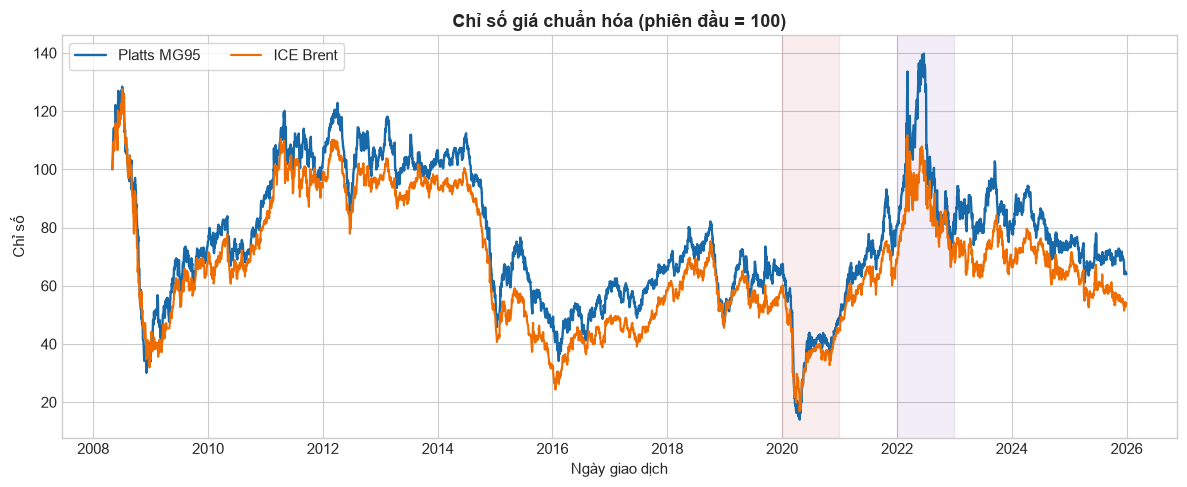

In [2]:
price_index = df.set_index("market_date")[["MG95", "brent_close"]].dropna()
price_index = price_index.div(price_index.iloc[0]).mul(100)
fig, ax = plt.subplots()
ax.plot(price_index.index, price_index["MG95"], label="Platts MG95", color="#1769aa", linewidth=1.7)
ax.plot(price_index.index, price_index["brent_close"], label="ICE Brent", color="#ef6c00", linewidth=1.5)
for year, color in [(2020, "#b71c1c"), (2022, "#6a1b9a")]:
    ax.axvspan(pd.Timestamp(f"{year}-01-01"), pd.Timestamp(f"{year}-12-31"), color=color, alpha=0.08)
ax.set(title="Chỉ số giá chuẩn hóa (phiên đầu = 100)", xlabel="Ngày giao dịch", ylabel="Chỉ số")
ax.legend(frameon=True, ncol=2)
fig.tight_layout()
plt.show()

## 3. Chênh lệch giá MG95–Brent

Chênh lệch dưới đây được định nghĩa là `MG95 - brent_close` theo giá đã ghép trong panel. Đây chỉ là **chênh lệch giá tham khảo**; không tính chi phí dầu đầu vào thực tế, hiệu suất lọc dầu, vận chuyển, tồn kho hay các điều kiện hợp đồng, nên không gọi là lợi nhuận lọc dầu ròng.

> **Ghi chú nói:** Dùng biểu đồ để chỉ ra chênh lệch thay đổi theo chu kỳ. Không diễn giải nó như lợi nhuận của một nhà máy lọc dầu cụ thể.

,Số phiên,Chênh lệch trung bình (USD/thùng),Chênh lệch min,Chênh lệch max
year,,,,
2020,252,3.41,-14.28,12.14
2022,250,16.16,-2.23,46.21


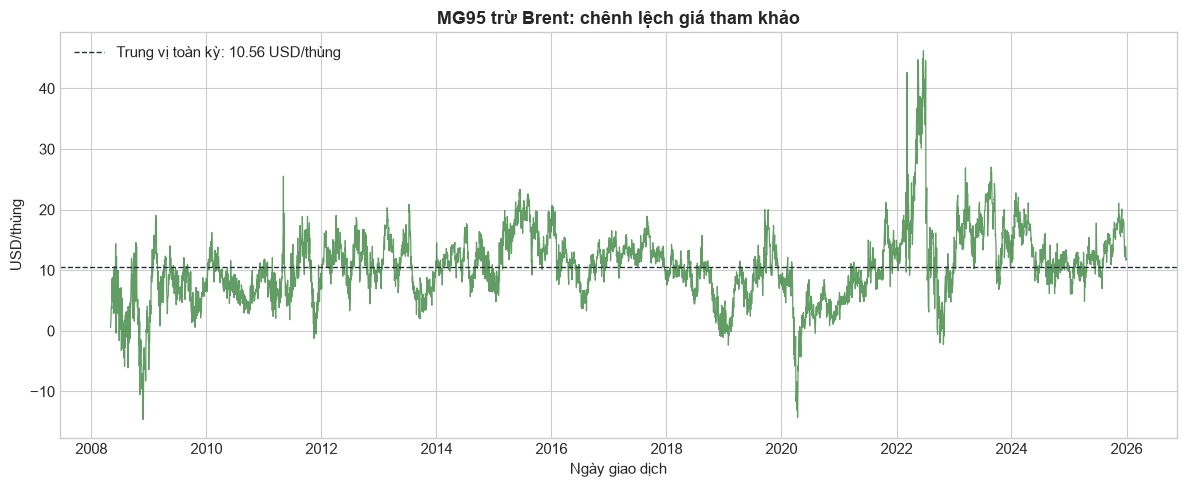

In [3]:
df["price_difference_proxy"] = df["MG95"] - df["brent_close"]
df["year"] = df["market_date"].dt.year
yearly_spread = df.groupby("year").agg(
    so_phien=("price_difference_proxy", "size"),
    chenh_lech_tb_usd_bbl=("price_difference_proxy", "mean"),
    chenh_lech_min=("price_difference_proxy", "min"),
    chenh_lech_max=("price_difference_proxy", "max"),
).round(2)
yearly_spread.columns = ["Số phiên", "Chênh lệch trung bình (USD/thùng)", "Chênh lệch min", "Chênh lệch max"]
display(yearly_spread.loc[[y for y in (2020, 2022) if y in yearly_spread.index]])

fig, ax = plt.subplots()
ax.plot(df["market_date"], df["price_difference_proxy"], color="#2e7d32", linewidth=0.9, alpha=0.75)
ax.axhline(df["price_difference_proxy"].median(), color="#263238", linestyle="--", linewidth=1,
           label=f"Trung vị toàn kỳ: {df['price_difference_proxy'].median():.2f} USD/thùng")
ax.set(title="MG95 trừ Brent: chênh lệch giá tham khảo", xlabel="Ngày giao dịch", ylabel="USD/thùng")
ax.legend()
fig.tight_layout()
plt.show()

## 4. Brent cùng phiên hay phiên trước đi cùng MG95 hơn?

Để tránh coi giá Brent được carry-forward vào ngày nghỉ là một quan sát mới, phép so sánh lợi suất chỉ dùng các ngày `brent_calendar_exact_match = True`. Độ trễ `t-1` bên dưới là **một phiên khớp lịch trước đó**, không nhất thiết là một ngày lịch.

Tương quan chỉ mô tả mức đồng biến tuyến tính trong mẫu này; nó không xác định chiều nhân quả và không phải kết quả dự báo ngoài mẫu.

> **Ghi chú nói:** So sánh hai con số tương quan và nói rõ định nghĩa phiên. Tránh phát biểu rằng tương quan lớn hơn đồng nghĩa Brent chắc chắn dự báo MG95.

,Tương quan Pearson
MG95(t) với Brent(t),0.249
MG95(t) với Brent(t-1 phiên khớp),0.572


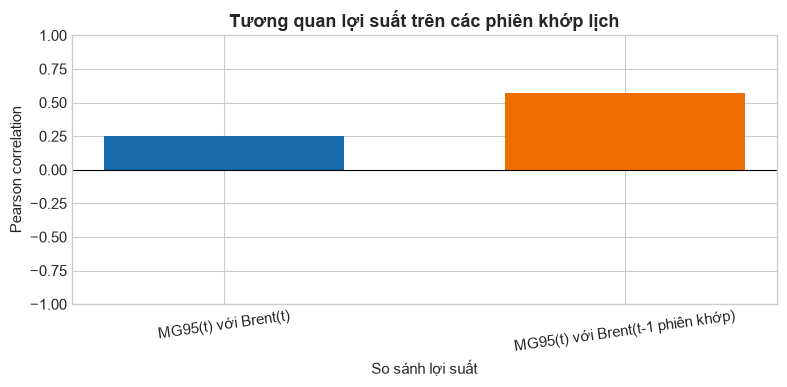

In [4]:
paired = df.loc[df["brent_calendar_exact_match"].fillna(False),
                ["market_date", "MG95", "brent_close"]].copy()
paired["r_mg95_pct"] = paired["MG95"].pct_change() * 100
paired["r_brent_pct"] = paired["brent_close"].pct_change() * 100
paired["r_brent_lag1_pct"] = paired["r_brent_pct"].shift(1)

corr_same = paired[["r_mg95_pct", "r_brent_pct"]].dropna().corr().iloc[0, 1]
corr_lag1 = paired[["r_mg95_pct", "r_brent_lag1_pct"]].dropna().corr().iloc[0, 1]
corr_table = pd.DataFrame({
    "So sánh lợi suất": ["MG95(t) với Brent(t)", "MG95(t) với Brent(t-1 phiên khớp)"],
    "Tương quan Pearson": [corr_same, corr_lag1],
}).set_index("So sánh lợi suất").round(3)
corr_table.index = ["MG95(t) với Brent(t)", "MG95(t) với Brent(t-1 phiên khớp)"]
corr_table.columns = ["Tương quan Pearson"]
display(corr_table)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(corr_table.index, corr_table.iloc[:, 0],
       color=["#1769aa", "#ef6c00"], width=0.6)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Tương quan lợi suất trên các phiên khớp lịch", xlabel="So sánh lợi suất", ylabel="Pearson correlation", ylim=(-1, 1))
ax.tick_params(axis="x", labelrotation=8)
fig.tight_layout()
plt.show()

## 5. Độ biến động trong các giai đoạn căng thẳng

Độ lệch chuẩn cuộn 30 quan sát được quy đổi theo căn bậc hai của 252 phiên/năm để dễ so sánh theo thời gian. Đây là thước đo mô tả; các cửa sổ đầu chuỗi chưa đủ 30 phiên sẽ không có giá trị.

> **Ghi chú nói:** Quan sát xem biến động có tăng quanh các giai đoạn 2020 và 2022 hay không. Không gọi một năm là “kỷ lục” nếu chưa so sánh đầy đủ và kiểm tra định nghĩa chỉ số.

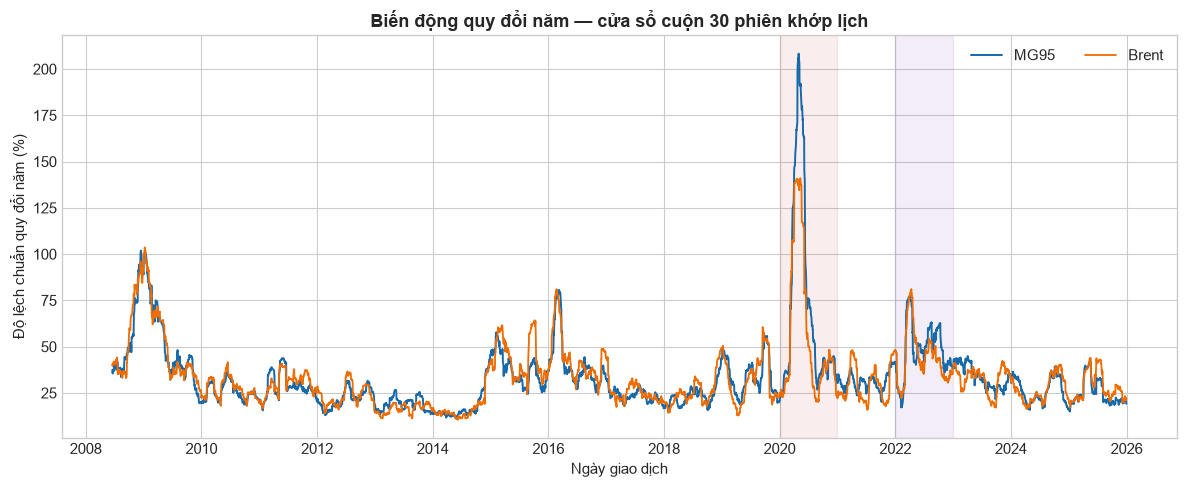

,MG95 biến động (%),Brent biến động (%)
year,,
2020,91.1,70.4
2022,50.7,46.3


In [5]:
paired["vol_mg95_30_pct"] = paired["r_mg95_pct"].rolling(30).std() * np.sqrt(252)
paired["vol_brent_30_pct"] = paired["r_brent_pct"].rolling(30).std() * np.sqrt(252)
fig, ax = plt.subplots()
ax.plot(paired["market_date"], paired["vol_mg95_30_pct"], label="MG95", color="#1769aa", linewidth=1.4)
ax.plot(paired["market_date"], paired["vol_brent_30_pct"], label="Brent", color="#ef6c00", linewidth=1.3)
for year, color in [(2020, "#b71c1c"), (2022, "#6a1b9a")]:
    ax.axvspan(pd.Timestamp(f"{year}-01-01"), pd.Timestamp(f"{year}-12-31"), color=color, alpha=0.08)
ax.set(title="Biến động quy đổi năm — cửa sổ cuộn 30 phiên khớp lịch", xlabel="Ngày giao dịch", ylabel="Độ lệch chuẩn quy đổi năm (%)")
ax.legend(ncol=2)
fig.tight_layout()
plt.show()

yearly_vol = paired.assign(year=paired["market_date"].dt.year).groupby("year").agg(
    mg95_vol_pct=("r_mg95_pct", lambda s: s.std() * np.sqrt(252)),
    brent_vol_pct=("r_brent_pct", lambda s: s.std() * np.sqrt(252)),
)
yearly_vol.columns = ["MG95 biến động (%)", "Brent biến động (%)"]
display(yearly_vol.loc[[y for y in (2020, 2022) if y in yearly_vol.index]].round(1))

## 6. Kết luận và giới hạn

1. **Dữ liệu phù hợp cho phân tích liên thị trường:** canonical panel giữ lại phần lớn phiên và ghi nhận minh bạch những ngày ghép Brent theo as-of.
2. **Hai chuỗi có thể cùng biến động nhưng không đồng nhất:** xem chuỗi giá chuẩn hóa, chênh lệch giá tham khảo và tương quan lợi suất để kể ba góc nhìn khác nhau.
3. **Cú sốc là một phần của câu chuyện:** kiểm tra các giai đoạn biến động cao thay vì xóa điểm cực đoan một cách máy móc.

### Giới hạn cần nói rõ
- Timestamp công bố/khả dụng là proxy; PIT audit qua kiểm tra theo timestamp trong pipeline nhưng không thay thế xác minh timestamp nguồn.
- Lợi suất `t-1` được tính theo phiên khớp lịch; không phải số ngày lịch cố định.
- Chênh lệch MG95–Brent không phải crack spread kế toán hay lợi nhuận ròng của nhà máy lọc dầu.
- Tương quan mô tả không chứng minh nhân quả; notebook chưa đánh giá hiệu quả dự báo ngoài mẫu.

> **Ghi chú kết:** Chốt bằng sự khác nhau giữa “cùng biến động”, “dẫn dắt” và “gây ra”. Để khẳng định dự báo cần kiểm định ngoài mẫu, còn để khẳng định nhân quả cần thiết kế nghiên cứu phù hợp.